# Dynamic NII, earnings at risk and EVaR under Hull-White and dynamic Nelson-Siegel scenarios

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 03 of this topic
- **Reading time:** about 50 minutes

## Objectives

By the end of this notebook you can:

- fit a Nelson-Siegel and a Svensson curve to the zero rates of a date, read their parameters and errors, and say what the dynamic Nelson-Siegel factors are;
- project the monthly net interest income (NII) of a book over 12 months under a constant balance sheet, with items that reset at different times and with a deposit beta;
- generate Hull-White one-factor short-rate scenarios and turn them into distributions of NII and EVE, and read earnings at risk (EaR) and economic value at risk (EVaR) with the Monte Carlo error of the quantile;
- explain why an EaR measured against a flat base can come out negative;
- compare each recomputation with the committed value, naming the engine version that baked it.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import curves, eve_nii, shocks, simulation, slotting
from riskvalidation.validation import irrbb as rv_irrbb

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
matplotlib 3.11.2


## Data

The data is case C14, the interest rate risk in the banking book (IRRBB) of the bank that failed in March 2023, as Contraste commits it: the FDIC call reports (FDIC BankFind financials, https://api.fdic.gov/banks/financials) and the US Treasury par curve (https://home.treasury.gov/resource-center/data-chart-center/interest-rates), public-domain sources of the licence class `mirror-allowed`. The bank is **real in aggregate and synthetic in behaviour**, so the repricing times, the deposit beta and the Hull-White mean reversion are stated or fitted by Contraste and labelled in the document. Money is in USD thousands, rates are decimals with continuous compounding, and a positive EaR, EVaR or delta NII is a loss.

- **Files read:** `data/derived/C14/vd-2022-q2.json` (`outputs.curve`, `dynamic_nii`, `ear_evar`, `balance_sheet`; `impact`), `vd-2021-q4.json` (`outputs.out_of_sample`, `curve`; `tests`) and `vd-2022-q4.json` (`outputs.curve`).
- **Not in the repository:** the quarterly history of the cost of deposits and of the Treasury curve, which the pipeline reads from the data root. Where the method needs a history of factors (Step 2), the notebook builds a **constructed, seeded** one and says so.

The next cell loads the three documents.

In [2]:
# Load the three valuation dates (the notebook sits three folders below the repository root) and the 19 midpoints
ROOT = Path("../../..").resolve()
docs = {q: json.loads((ROOT / "data" / "derived" / "C14" / f"vd-{q.lower()}.json").read_text(encoding="utf-8")) for q in ("2021-Q4", "2022-Q2", "2022-Q4")}
out = docs["2022-Q2"]["outputs"]
MID = slotting.bucket_grid().midpoints
LANG = "en"  # the bilingual fields of the documents are read in this language
# Names of the document's own values in this language (the identifiers of the file stay as they are)
NAME = {"base": "base", "parallel-up": "parallel up", "parallel-down": "parallel down", "asset": "asset",
        "liability": "liability", True: "yes", False: "no"}
for q, d in docs.items():
    print(q, d["outputs"]["valuation_date"], "| baked by riskvalidation", d["provenance"]["riskvalidation_version"], "| installed", rv.__version__)

2021-Q4 2021-12-31 | baked by riskvalidation 0.8.1 | installed 0.8.1
2022-Q2 2022-06-30 | baked by riskvalidation 0.8.1 | installed 0.8.1
2022-Q4 2022-12-31 | baked by riskvalidation 0.8.1 | installed 0.8.1


## Method

The method has five steps: (1) fit parametric curves, (2) the dynamic Nelson-Siegel factors and their forecast, (3) the monthly NII of the book, (4) Hull-White scenarios and the distributions of NII and EVE, (5) the out-of-sample check of the projection.

### Step 1: Nelson-Siegel and Svensson

A parametric curve describes the whole yield curve with a few numbers. The Nelson-Siegel curve gives the yield at maturity $m$ with four parameters, a level, a slope, a curvature and a decay $\tau$ (Nelson and Siegel, 1987, https://doi.org/10.1086/296409; dossier 05, D.5):

$$y(m) = \beta_0 + \beta_1\, \frac{1 - e^{-m/\tau}}{m/\tau} + \beta_2 \left( \frac{1 - e^{-m/\tau}}{m/\tau} - e^{-m/\tau} \right)$$

Svensson adds a second hump, $\beta_3 \left( \frac{1 - e^{-m/\tau_2}}{m/\tau_2} - e^{-m/\tau_2} \right)$ (Svensson, 1994, https://doi.org/10.3386/w4871). For a fixed $\tau$ the curve is linear in the betas, so the engine's `fit_nelson_siegel` solves least squares for each $\tau$ of a grid (0.25 to 10 years in steps of 0.25) and keeps the best; `fit_svensson` does a grid search over the two decays followed by a bounded polish, and nests Nelson-Siegel, so its error is never above. The next cell fits both to the 12 zero rates of 2022-06-30 and prints the parameters and the root mean square error in basis points.

In [3]:
# Fit Nelson-Siegel and Svensson to the 12 committed zero rates of 2022-06-30 and print the parameters and the error
points = out["curve"]["points"]
tenors = np.array([p["tenor_years"] for p in points])
zero = np.array([p["zero_rate"] for p in points])
ns = curves.fit_nelson_siegel(tenors, zero)
sv = curves.fit_svensson(tenors, zero)
print(f"Nelson-Siegel: β0 {ns.beta0:.5f} β1 {ns.beta1:.5f} β2 {ns.beta2:.5f} τ {ns.tau:.2f} | error (bp) {ns.rmse * 1e4:.2f}")
print(f"Svensson:      β0 {sv.beta0:.5f} β1 {sv.beta1:.5f} β2 {sv.beta2:.5f} β3 {sv.beta3:.5f} τ1 {sv.tau1:.3f} τ2 {sv.tau2:.3f} | error (bp) {sv.rmse * 1e4:.2f}")
print("the Svensson error is not above the Nelson-Siegel one:", NAME[sv.rmse <= ns.rmse], "| τ of Nelson-Siegel on the edge of the grid (0.25):", NAME[ns.tau == curves.DEFAULT_TAU_GRID[0]])
ns_fit = curves.nelson_siegel_yield(tenors, ns.beta0, ns.beta1, ns.beta2, ns.tau)
sv_fit = curves.svensson_yield(tenors, sv.beta0, sv.beta1, sv.beta2, sv.beta3, sv.tau1, sv.tau2)
print(f"{'tenor (y)':>14s} {'zero rate':>14s} {'Nelson-Siegel':>14s} {'Svensson':>10s}")
for k in range(len(tenors)):
    print(f"{tenors[k]:14.4f} {zero[k]:14.5f} {ns_fit[k]:14.5f} {sv_fit[k]:10.5f}")

Nelson-Siegel: β0 0.03131 β1 -0.02332 β2 0.00855 τ 0.25 | error (bp) 12.59
Svensson:      β0 0.01526 β1 -0.00569 β2 0.04614 β3 0.05473 τ1 0.608 τ2 11.472 | error (bp) 10.09
the Svensson error is not above the Nelson-Siegel one: yes | τ of Nelson-Siegel on the edge of the grid (0.25): yes
     tenor (y)      zero rate  Nelson-Siegel   Svensson
        0.0833        0.01279        0.01262    0.01302
        0.1667        0.01678        0.01614    0.01595
        0.2500        0.01716        0.01883    0.01842
        0.5000        0.02494        0.02377    0.02371
        1.0000        0.02783        0.02753    0.02844
        2.0000        0.02902        0.02946    0.02963
        3.0000        0.02972        0.03008    0.02909
        5.0000        0.02991        0.03057    0.02913
        7.0000        0.03022        0.03079    0.03001
       10.0000        0.02955        0.03094    0.03136
       20.0000        0.03445        0.03113    0.03282
       30.0000        0.03068        0.

### Step 2: dynamic Nelson-Siegel

Diebold and Li (2006, https://doi.org/10.1016/j.jeconom.2005.03.005) fix the decay and let the three betas move over time as a **level**, a **slope** and a **curvature** factor, each following an AR(1), which gives a forecasting model for whole curves. With the decay $\lambda = 0.0609$ per month and maturities $m$ in months, the loadings of the three factors are

$$y_t(m) = L_t + S_t\, \frac{1 - e^{-\lambda m}}{\lambda m} + C_t \left( \frac{1 - e^{-\lambda m}}{\lambda m} - e^{-\lambda m} \right), \qquad f_{t+1} = c + \phi\, f_t + \varepsilon_t$$

The paper says the decay was chosen to maximise the curvature loading at exactly 30 months; the engine documents that the maximum is at 29.446 months and that the paper rounds. The next cell checks it on a fine grid with the engine's own loadings, and then fits the three factors at each of the three committed dates by least squares on the tenors they share (`fit_dns_factors`). The level should rise through the 2022 hiking cycle.

In [4]:
# Find the maximum of the curvature loading on a fine grid, then fit the three factors at the three dates on the shared tenors
fine = np.arange(1.0, 120.0, 0.001)
loadings = curves.dns_loadings(fine)
print("λ =", curves.DIEBOLD_LI_LAMBDA, "| curvature loading peaks at (months):", round(float(fine[np.argmax(loadings[:, 2])]), 3))
shared_years = np.array([0.25, 0.5, 1.0, 2.0, 3.0, 5.0, 7.0, 10.0, 20.0, 30.0])
months = np.round(shared_years * 12)
panel = []
for q, d in docs.items():
    by_tenor = {round(p["tenor_years"], 2): p["zero_rate"] for p in d["outputs"]["curve"]["points"]}
    panel.append([by_tenor[round(float(y), 2)] for y in shared_years])
factors = curves.fit_dns_factors(months, np.array(panel))
print(f"{'':8s} {'level':>9s} {'slope':>11s} {'curvature':>11s}")
for q, f in zip(docs, factors):
    print(f"{q:8s} {f[0]:9.5f} {f[1]:11.5f} {f[2]:11.5f}")

λ = 0.0609 | curvature loading peaks at (months): 29.446
             level       slope   curvature
2021-Q4    0.02068    -0.02086    -0.00942
2022-Q2    0.03095    -0.01271     0.01523
2022-Q4    0.03837     0.00875     0.00005


To forecast, the model needs a history of factors, at least four dates. The committed documents hold three dates only, and the pipeline's full history is not in the repository, so the next cell builds a **constructed, seeded history** of 48 months of AR(1) factors around the 2022-Q2 values, not data of the bank. It calls `forecast_dns_factors` (an AR(1) fitted to each factor by least squares, independent Gaussian innovations of the fitted residual variance, paths that start from the last row of the history and use nothing later) and `dns_scenarios` (the same paths through the loadings into yields at chosen maturities), and prints the spread of the 12-month-ahead level and of the 10-year yield.

In [5]:
# A constructed, seeded factor history, the forecast of the factors and the yields at 12 months ahead
rng = np.random.default_rng(42)
center = factors[1]
history = np.zeros((48, 3))
history[0] = center
for t in range(1, 48):
    history[t] = center + 0.9 * (history[t - 1] - center) + rng.normal(0, [0.0015, 0.002, 0.003])
paths = curves.forecast_dns_factors(history, 12, 2000, 42)
print("factor paths (paths, months, factors):", paths.shape)
print("level at month 12: mean and 5th and 95th percentiles:", np.round([paths[:, -1, 0].mean(), *np.percentile(paths[:, -1, 0], [5, 95])], 5))
yields = simulation.dns_scenarios(history, np.array([12.0, 60.0, 120.0]), 12, 2000, 42)
print("yield paths (paths, months, maturities):", yields.shape)
print("10-year yield at month 12: mean and 5th and 95th percentiles:", np.round([yields[:, -1, 2].mean(), *np.percentile(yields[:, -1, 2], [5, 95])], 5))
print("the same paths: factors through the loadings equal dns_scenarios:", NAME[bool(np.allclose(paths @ curves.dns_loadings(np.array([12.0, 60.0, 120.0])).T, yields))])

factor paths (paths, months, factors): (2000, 12, 3)
level at month 12: mean and 5th and 95th percentiles: [0.03122 0.02821 0.03415]
yield paths (paths, months, maturities): (2000, 12, 3)
10-year yield at month 12: mean and 5th and 95th percentiles: [0.03124 0.02804 0.03442]
the same paths: factors through the loadings equal dns_scenarios: yes


### Step 3: the monthly NII of the book

The dynamic NII projects the net interest income month by month over 12 months. Each interest-bearing item has a balance, a side (asset or liability), a current rate and a reset rule: after its reset month $k$ the item earns $\text{spread} + \beta\, r$, where $r$ is the short rate at the month of its latest reset and $\beta$ is the pass-through (1 for an asset indexed to the market, the deposit beta for a deposit). An item with $k = 0$ resets every month; an item with $k \ge 1$ keeps its current rate for the months before $k$ and then resets at $k, 2k, \dots$. The monthly NII is

$$NII_m = \frac{1}{12} \sum_i \text{side}_i\ B_i\, (1 + g)^{m/12}\ \text{rate}_{i,m}$$

with $g$ the annual growth of the balance sheet; $g = 0$ is the **constant balance sheet** of the standard (maturing and repricing flows replaced by identical new ones, BCBS d368 DIS70.5; dossier 05, D.6). The call report does not give the reset times, so the pipeline states them: 2 months for the band of three months or less, 8 months for three to twelve months, beyond the horizon for the rest (synthetic, in the document). The next cell lists the ten items of the 2022-Q2 projection.

In [6]:
# List the ten items of the dynamic NII with their balance, rate, spread, beta and reset month
dyn = out["dynamic_nii"]
items = dyn["items"]
print(dyn["balance_sheet_assumption"]["description"][LANG])
print(f"{'':4s} {'side':9s} {'balance':>14s} {'rate':>8s} {'spread':>8s} {'beta':>6s} {'reset (months)':>20s}")
for it in items:
    print(f"{it['item_id']:4s} {NAME[it['side']]:9s} {it['balance']:14,.0f} {it['rate0']:8.4f} {it['spread']:8.4f} {it['beta']:6.3f} {it['reprice_months']:20d}")

Constant balance sheet: maturing and repricing flows are replaced by identical new ones. Non-interest items are left out.
     side             balance     rate   spread   beta       reset (months)
D1   asset         14,808,000   0.0041  -0.0087  1.000                    0
D2   asset         55,065,000   0.0310   0.0182  1.000                    2
D3   asset          3,777,000   0.0310   0.0182  1.000                    8
D4   asset         12,019,000   0.0310   0.0310  0.000                  120
D5   asset             50,000   0.0187   0.0059  1.000                    2
D6   asset            556,000   0.0187   0.0059  1.000                    8
D7   asset        121,338,000   0.0187   0.0187  0.000                  120
D8   liability    116,177,000   0.0000   0.0000  0.000                    0
D9   liability     73,976,000   0.0027   0.0017  0.075                    0
D10  liability      3,703,000   0.0128   0.0000  1.000                    0


The engine's `simulate_nii` takes the arrays of the items and a short-rate path of 12 to 36 months. The committed scenarios use a flat path: the short rate of the date (the zero rate of the second band) plus the shock, floored at zero (200 bp up, 200 bp down), kept for the 12 months. The next cell rebuilds the three paths with `apply_floor`, runs `simulate_nii` on each, and compares the monthly NII and the total with the committed scenarios. The delta against the base is loss-positive: a negative number is a gain.

In [7]:
# Run the engine's simulate_nii on the three flat paths and compare with the committed scenarios
balance = np.array([it["balance"] for it in items])
side = np.array([1 if it["side"] == "asset" else -1 for it in items])
rate0 = np.array([it["rate0"] for it in items])
spread = np.array([it["spread"] for it in items])
beta = np.array([it["beta"] for it in items])
reset = np.array([it["reprice_months"] for it in items])
r0 = np.array(out["curve"]["zero_rates_at_midpoints"])
r_short = float(r0[1])
floor = out["scenarios"][0]["floor"]
result = {}
for committed in dyn["scenarios"]:
    start = float(shocks.apply_floor(np.array([r_short]), np.array([committed["shock_bp"]]), floor)[0])
    path = np.full(12, start)
    result[committed["scenario"]] = simulation.simulate_nii(balance, side, rate0, spread, beta, reset, path, 0.0)
    same = np.allclose(result[committed["scenario"]].monthly_nii, committed["monthly_nii"]) and np.allclose(path, committed["short_rate_path"])
    print(f"{NAME[committed['scenario']]:16s} short rate {start:.5f} | NII 12 months {result[committed['scenario']].total:14,.0f} | delta vs base {result['base'].total - result[committed['scenario']].total:14,.0f} | equal to the committed {NAME[bool(same)]}")

base             short rate 0.01279 | NII 12 months      4,297,741 | delta vs base              0 | equal to the committed yes
parallel up      short rate 0.03279 | NII 12 months      5,356,610 | delta vs base     -1,058,869 | equal to the committed yes
parallel down    short rate 0.00000 | NII 12 months      3,620,426 | delta vs base        677,315 | equal to the committed yes


The same function accepts the annual growth of the balance sheet. A growing balance sheet scales every month by $(1 + g)^{m/12}$, so with $g = 5$ percent the NII of the 12 months is higher than with the constant balance sheet. The next cell shows the monthly profile under the base path, the two shocks and the growth, which the last figure draws.

In [8]:
# Monthly NII under the base path and the growth of the balance sheet, month by month for the first and the last months
base_path = np.full(12, r_short)
grown = simulation.simulate_nii(balance, side, rate0, spread, beta, reset, base_path, 0.05)
print(f"{'month':>6s} {'base':>14s} {'+200 bp':>14s} {'-200 bp':>14s} {'growth 5%':>16s}")
for m in (0, 1, 2, 5, 8, 11):
    print(f"{m + 1:6d} {result['base'].monthly_nii[m]:14,.0f} {result['parallel-up'].monthly_nii[m]:14,.0f} {result['parallel-down'].monthly_nii[m]:14,.0f} {grown.monthly_nii[m]:16,.0f}")
print("NII 12 months with growth 5%:", round(grown.total), "| constant balance sheet:", round(result["base"].total))

 month           base        +200 bp        -200 bp        growth 5%
     1        358,145        367,428        352,207          358,145
     2        358,145        367,428        352,207          359,604
     3        358,145        459,287        293,449          361,069
     6        358,145        459,287        293,449          365,500
     9        358,145        466,508        288,830          369,986
    12        358,145        466,508        288,830          374,526
NII 12 months with growth 5%: 4395363 | constant balance sheet: 4297741


### Step 4: Hull-White scenarios, EaR and EVaR

A distribution of NII and EVE needs a distribution of rate paths. The Hull-White one-factor model has the short rate $r(t) = x(t) + \alpha(t)$ with $dx = -a\, x\, dt + \sigma\, dW$, $x(0) = 0$, and a deterministic part chosen to fit today's curve (Hull and White, 1990, https://doi.org/10.1093/rfs/3.4.573; the engine's form is the textbook one, Brigo and Mercurio, 2006, eq. 3.34):

$$\alpha(t) = f(0, t) + \frac{\sigma^2}{2 a^2}\, \left(1 - e^{-a t}\right)^2$$

with $f(0,t)$ the instantaneous forward rate of the initial curve. The engine's `hw1f_scenarios` simulates the monthly grid exactly and uses antithetic paths (the second half mirrors the first). The pipeline sets the mean reversion $a$ at 0.10 a year (stated, synthetic) and fits $\sigma$ to the daily changes of the 3-month Treasury yield over the last three years. For each path it computes the NII of the 12 months with `simulate_nii` and the EVE of the behavioural flows under the parallel shift implied by the path (the change of the short rate over the year, floored): that composition is the bake's design, not an engine function. Then `ear_evar` takes the loss-positive difference between the base and the $(1 - \text{level})$ quantile:

$$EaR = NII_{base} - Q_{1-\text{level}}(NII), \qquad EVaR = EVE_{base} - Q_{1-\text{level}}(EVE)$$

The committed run has 100,000 paths and seed 42. It takes a few seconds, so the next cell reproduces it exactly and compares the 95 and 99 percent levels with the committed values.

In [9]:
# Reproduce the committed Hull-White run: 100,000 antithetic paths, NII and EVE per path, EaR and EVaR with their Monte Carlo error
dist = out["ear_evar"]
a_hw, sigma_hw = (p["value"] for p in dist["parameters"])
ten = tenors
zero_curve = zero
flows = np.zeros(19)
for it in out["balance_sheet"]["items"]:
    for row in it["cash_flows"]["behavioural"]:
        flows[row["bucket"] - 1] += row["amount"]
rates = simulation.hw1f_scenarios(zero_curve, ten, a_hw, sigma_hw, dist["horizon_months"], dist["n_paths"], dist["seed"])
nii_paths = np.array([simulation.simulate_nii(balance, side, rate0, spread, beta, reset, q[:12], 0.0).total for q in rates])
eve_paths = np.array([eve_nii.eve(flows, shocks.apply_floor(r0, np.full(19, (q[-1] - q[0]) * 1e4), floor), MID) for q in rates])
base_nii, base_eve = dist["base_nii"], dist["base_eve"]
print("a =", a_hw, "| σ =", round(sigma_hw, 6), "| paths", rates.shape[0], "| seed", dist["seed"], "| base NII", round(base_nii), "| base EVE", round(base_eve))
for level in dist["levels"]:
    got = simulation.ear_evar(nii_paths, eve_paths, base_nii, base_eve, level["level"])
    err = simulation.ear_evar_mc_error(nii_paths, eve_paths, level["level"], dist["n_batches"], antithetic=True)
    same = np.allclose([got.ear, got.evar, err.ear_se, err.evar_se], [level["ear"], level["evar"], level["ear_se"], level["evar_se"]])
    print(f"level {level['level']:.2f}: EaR {got.ear:12,.0f} (±{err.ear_se:,.0f}) | EVaR {got.evar:12,.0f} (±{err.evar_se:,.0f}) | equal to the committed {NAME[bool(same)]}")

a = 0.1 | σ = 0.00504 | paths 100000 | seed 42 | base NII 4297741 | base EVE 7036780
level 0.95: EaR     -585,961 (±995) | EVaR    3,948,056 (±4,285) | equal to the committed yes
level 0.99: EaR     -482,023 (±1,451) | EVaR    4,370,301 (±6,623) | equal to the committed yes


Two readings. First, the EaR at both levels is **negative**: the NII at the 1 percent quantile is above the base NII. The base projection holds the short rate flat at today's 1.28 percent, while the Hull-White paths follow the forward curve, which at mid-2022 was upward-sloping, so the distribution of NII is centred well above the base. An EaR measured against a flat base therefore says that the earnings would be higher in 99 percent of the paths, not that there is no risk; the downside has to be read against the distribution's own centre. The next cell prints the mean and the quantiles of the paths and of the NII. Second, the quantile has a Monte Carlo error that falls with the number of paths. The cell after it repeats the run with fewer paths (new antithetic draws of 2,000 and 10,000 paths) and prints each error beside the committed one of the 100,000 paths.

In [10]:
# Where the distribution sits: the short rate at month 12 and the NII of the paths against the flat base
print("short rate today and at month 12 (mean, 5th and 95th percentiles):", round(float(rates[:, 0].mean()), 5), np.round([rates[:, -1].mean(), *np.percentile(rates[:, -1], [5, 95])], 5))
print("NII of the 12 months: base, mean of the paths, 1st, 5th and 95th percentiles:", round(base_nii), round(float(nii_paths.mean())), np.round(np.percentile(nii_paths, [1, 5, 95])))
print("share of the paths with NII above the base:", round(float((nii_paths > base_nii).mean()), 4))

short rate today and at month 12 (mean, 5th and 95th percentiles): 0.01279 [0.02903 0.02117 0.03689]
NII of the 12 months: base, mean of the paths, 1st, 5th and 95th percentiles: 4297741 5138757 [4779764. 4883702. 5393813.]
share of the paths with NII above the base: 1.0


The second reading: the Monte Carlo error. The next cell repeats the run with 2,000 and 10,000 paths and prints each 99 percent estimate with its error, beside the committed 100,000.

In [11]:
# The Monte Carlo error of the 99 percent EaR and EVaR with 2,000, 10,000 and the committed 100,000 antithetic paths
print(f"{'paths':>12s} {'EaR 99':>12s} {'error':>8s} {'EVaR 99':>12s} {'error':>8s}")
for n in (2000, 10000):
    sample = simulation.hw1f_scenarios(zero_curve, ten, a_hw, sigma_hw, 12, n, dist["seed"])
    nii_n = np.array([simulation.simulate_nii(balance, side, rate0, spread, beta, reset, q[:12], 0.0).total for q in sample])
    eve_n = np.array([eve_nii.eve(flows, shocks.apply_floor(r0, np.full(19, (q[-1] - q[0]) * 1e4), floor), MID) for q in sample])
    got = simulation.ear_evar(nii_n, eve_n, base_nii, base_eve, 0.99)
    err = simulation.ear_evar_mc_error(nii_n, eve_n, 0.99, 20, antithetic=True)
    print(f"{n:12,d} {got.ear:12,.0f} {err.ear_se:8,.0f} {got.evar:12,.0f} {err.evar_se:8,.0f}")
c99 = dist["levels"][1]
print(f"{dist['n_paths']:12,d} {c99['ear']:12,.0f} {c99['ear_se']:8,.0f} {c99['evar']:12,.0f} {c99['evar_se']:8,.0f}  ({'committed'})")

       paths       EaR 99    error      EVaR 99    error
       2,000     -480,611    7,071    4,305,713   30,669
      10,000     -480,337    5,715    4,356,301   22,474
     100,000     -482,023    1,451    4,370,301    6,623  (committed)


### Step 5: the out-of-sample check

A projection earns trust by being compared with what happened. The projection made at 2021-12-31 for a +200 bp shock (the loss-positive change in NII over 12 months) can be compared with the change in NII the bank realised in 2022 from the call reports. The engine's test `irrbb.nii_out_of_sample` takes the projected and the realised change and returns the relative error with a light (green at most 10 percent, amber at most 25 percent, red above: Contraste internal gates). The valuation dates of 2022-06-30 and 2022-12-31 have no realised year after them, because the bank failed on 2023-03-10 and filed no later report: the document says so and the test returns `not_evaluated` rather than a number. The next cell runs the test on the 2021-Q4 pair and compares with the committed row, then prints the reason the other two dates give.

In [12]:
# Run the out-of-sample test on the 2021-Q4 projection and show why the other two dates are not evaluated
oos = docs["2021-Q4"]["outputs"]["out_of_sample"]
result_oos = rv_irrbb.nii_out_of_sample(oos["projected_delta_nii"], oos["realised_delta_nii"])
print(f"2021-Q4: projected delta NII (loss positive) {oos['projected_delta_nii']:,.0f} | realised {oos['realised_delta_nii']:,.0f} ({oos['realised_period_start']} to {oos['realised_period_end']})")
print(f"relative error {result_oos.statistic:.4f} | difference in money {result_oos.metric:,.0f} | light {result_oos.light.value}")
committed = next(t for t in docs["2021-Q4"]["tests"] if t["test_id"] == "irrbb.nii_out_of_sample")
print("committed row: light, relative error:", committed["light"], round(committed["statistic"], 4), "| equal:", NAME[bool(np.isclose(committed["statistic"], result_oos.statistic) and committed["light"] == result_oos.light.value)])
for q in ("2022-Q2", "2022-Q4"):
    row = next(t for t in docs[q]["tests"] if t["test_id"] == "irrbb.nii_out_of_sample")
    print(q, row["light"], "|", docs[q]["outputs"]["out_of_sample"]["reason"][LANG])

2021-Q4: projected delta NII (loss positive) -1,138,367 | realised -1,358,000 (2022-01-01 to 2022-12-31)
relative error 0.1617 | difference in money 219,633 | light amber
committed row: light, relative error: amber 0.1617 | equal: yes
2022-Q2 not_evaluated | No realised year follows this date in the call reports: the bank failed on 2023-03-10 and filed no later report, so the 12-month projection cannot be compared with a realised one.
2022-Q4 not_evaluated | No realised year follows this date in the call reports: the bank failed on 2023-03-10 and filed no later report, so the 12-month projection cannot be compared with a realised one.


The last cell draws, from the left, the fitted curves against the zero rates, the monthly NII under the base path, the two shocks and the growth, and the distribution of the 12-month NII of the Hull-White paths with the base and the 1 percent quantile. On the left the Svensson curve follows the 20-year hump that the Nelson-Siegel curve cannot. In the middle the up shock lifts the NII from the first reset, and the down shock lowers it. On the right the whole distribution lies to the right of the flat base.

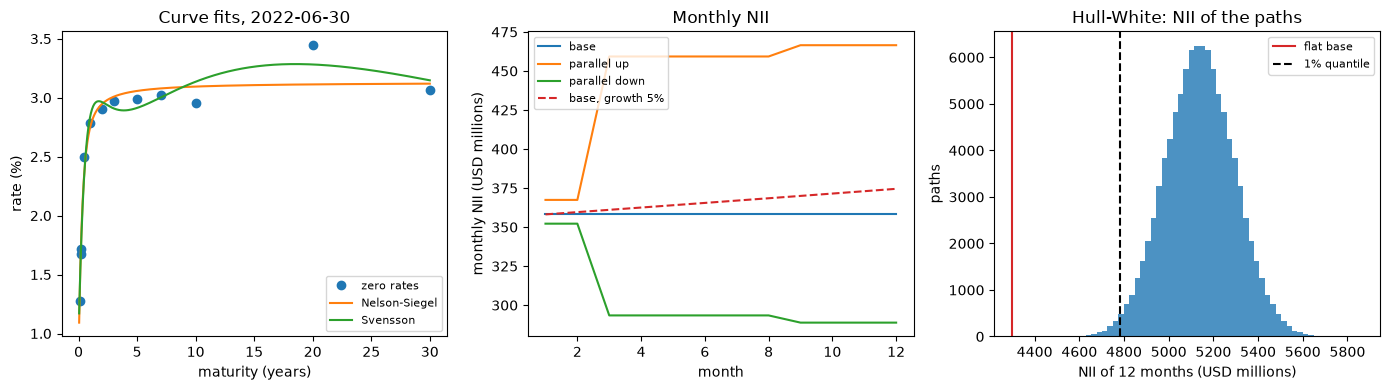

In [13]:
# Draw the curve fits, the monthly NII under the scenarios and the distribution of the 12-month NII
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(14, 4))
grid = np.linspace(0.05, 30, 300)
a1.plot(tenors, zero * 100, "o", label="zero rates")
a1.plot(grid, curves.nelson_siegel_yield(grid, ns.beta0, ns.beta1, ns.beta2, ns.tau) * 100, label="Nelson-Siegel")
a1.plot(grid, curves.svensson_yield(grid, sv.beta0, sv.beta1, sv.beta2, sv.beta3, sv.tau1, sv.tau2) * 100, label="Svensson")
a1.set_xlabel("maturity (years)")
a1.set_ylabel("rate (%)")
a1.set_title("Curve fits, 2022-06-30")
a1.legend(fontsize=8)
months_axis = np.arange(1, 13)
for key in ("base", "parallel-up", "parallel-down"):
    a2.plot(months_axis, result[key].monthly_nii / 1e3, label=NAME[key])
a2.plot(months_axis, grown.monthly_nii / 1e3, linestyle="--", label="base, growth 5%")
a2.set_xlabel("month")
a2.set_ylabel("monthly NII (USD millions)")
a2.set_title("Monthly NII")
a2.legend(fontsize=8)
a3.hist(nii_paths / 1e3, bins=60, color="tab:blue", alpha=0.8)
a3.axvline(base_nii / 1e3, color="tab:red", label="flat base")
a3.axvline(np.percentile(nii_paths, 1) / 1e3, color="black", linestyle="--", label="1% quantile")
a3.set_xlabel("NII of 12 months (USD millions)")
a3.set_ylabel("paths")
a3.set_title("Hull-White: NII of the paths")
a3.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Results

- **The curve fits.** Nelson-Siegel fits the 12 zero rates of 2022-06-30 with an error of 12.59 bp and Svensson with 10.09 bp, so the second hump buys 2.5 bp. Both miss the 20-year point (3.445 percent against 3.113 and 3.282 percent) and the short end (the 3-month rate 1.716 percent against 1.883 and 1.842 percent). The Nelson-Siegel decay is 0.25 years, the lowest value of its grid: the best fit wants a faster decay than the grid allows, so the result depends on the grid and a validator should widen it before trusting the betas. A fitted curve is a model of the market curve, not the market curve.
- **Dynamic Nelson-Siegel.** The curvature loading peaks at 29.446 months with the decay of 0.0609, not at the exactly 30 the paper rounds to. The three factors move as the hiking cycle advances: the level rises from 2.07 to 3.10 and to 3.84 percent, and the slope factor from -2.09 to -1.27 and to +0.88 percent, the move from an upward-sloping curve to an inverted one. The forecast in the next cell comes from a constructed history, so its spread (the 12-month level between 2.82 and 3.42 percent) shows how the function works and says nothing about the bank.
- **The monthly NII.** The base 12-month NII is 4,297,741. With a +200 bp shock it is 5,356,610, a gain of 1,058,869; with a -200 bp shock the zero floor stops the short rate at 0 percent, 128 bp below today's, and the NII is 3,620,426, a loss of 677,315. The items that reset every month move at once, the 2-month items from month 3 and the 8-month items from month 9. Every figure equals the committed scenario. These signs are the opposite of notebook 01's repricing gap, which gave a loss of 199,057 for +100 bp: the gap treats the part of the deposits it places overnight as repricing at the full shock, while the projection gives the interest-bearing deposits a beta of 0.075 and the non-interest-bearing ones none. The earnings effect of a rate rise is therefore as much a statement about the deposit beta as about the book (notebook 07 compares the two on the three dates).
- **EaR and EVaR.** With 100,000 antithetic paths and the committed seed, the run equals the committed one: EaR is -585,961 at 95 percent and -482,023 at 99 percent, EVaR is 3,948,056 and 4,370,301. The EaR is negative because every one of the paths has a higher NII than the flat base: the short rate has a mean of 2.90 percent at month 12 (5th to 95th percentile 2.12 to 3.69 percent) against 1.28 percent today, since Hull-White follows the forward curve, and the mean NII of the paths is 5,138,757, 20 percent above the base. The honest reading is that the earnings are not at risk against a base that stands still, and that the base is the weak side of the measure. The EVaR is 4,370,301 at 99 percent, 62 percent of the base EVE of 7,036,780.
- **The Monte Carlo error.** The 99 percent EVaR is 4,305,713 with 2,000 paths (error 30,669), 4,356,301 with 10,000 (22,474) and 4,370,301 with 100,000 (6,623). The error falls with the number of paths, though not smoothly, because it is itself estimated from 20 batches, and the estimates stay within a few errors of the committed run. Fewer paths would also leave the estimate of the tail itself noisy: a validator reads the error beside the estimate, and the engine makes that easy by returning it.
- **The out-of-sample check.** At 2021-12-31 the projection for +200 bp was a change of -1,138,367 (a gain) against a realised change of -1,358,000 in 2022: a relative error of 16.2 percent, amber. It compares a shock with a path, so it checks the order of magnitude and the sign of the sensitivity, not the forecast. At 2022-06-30 and 2022-12-31 there is no realised year, and the test is `not_evaluated` with the reason written, never a number.
- **What the notebook does not show.** The fit of the pass-through to the bank's history and the stability of the replicating weights (notebook 05), the three-date comparison with the gap and duration approximations (notebook 07), and any forecast of the bank's real rates: the history of factors is constructed.

## Summary

- A parametric curve compresses a yield curve into four or six numbers; Svensson nests Nelson-Siegel and never fits worse, and the Nelson-Siegel decay can sit on the edge of its grid.
- The dynamic Nelson-Siegel makes the three factors AR(1) series and turns a history of factors into scenarios of whole curves; here the history is constructed, because the bank's quarterly history is not in the repository.
- The monthly NII of the book depends on when each item resets and on the deposit beta; the engine reproduces the committed projections exactly, and the constant balance sheet is the standard's assumption.
- EaR and EVaR are quantile differences from simulated paths, with a Monte Carlo error that falls with the number of paths; an EaR against a flat base can be negative when the scenarios follow an upward forward curve.
- A projection is compared with the realised year when there is one; the bank filed no later report, so two of the three dates have none, and the engine says so instead of returning a number.

**What to try next.** Change the mean reversion `a_hw` and watch how the spread of the 12-month rate moves the EVaR more than the EaR. Then continue with notebook 05, the validation tests.

## References

- Nelson, C. R. and Siegel, A. F. (1987), Parsimonious modeling of yield curves, Journal of Business 60(4). https://doi.org/10.1086/296409
- Svensson, L. E. O. (1994), Estimating and interpreting forward interest rates: Sweden 1992-1994, NBER Working Paper 4871. https://doi.org/10.3386/w4871
- Diebold, F. X. and Li, C. (2006), Forecasting the term structure of government bond yields, Journal of Econometrics 130(2). https://doi.org/10.1016/j.jeconom.2005.03.005
- Hull, J. and White, A. (1990), Pricing interest-rate-derivative securities, Review of Financial Studies 3(4). https://doi.org/10.1093/rfs/3.4.573
- Brigo, D. and Mercurio, F. (2006), Interest Rate Models, Theory and Practice, Springer (equation 3.34, as cited by the engine; the edition is not verified).
- BCBS (2016), d368, Standards: Interest rate risk in the banking book, DIS70.5 (the constant balance sheet). https://www.bis.org/bcbs/publ/d368.htm
- BCBS, Standards: Interest rate risk in the banking book, SRP31. https://www.bis.org/basel_framework/chapter/SRP/31.htm
- FDIC, BankFind financials, public domain. https://api.fdic.gov/banks/financials
- US Department of the Treasury, Daily Treasury Par Yield Curve Rates, public domain. https://home.treasury.gov/resource-center/data-chart-center/interest-rates
- Dossier 05 of the Contraste research, sections C.4, D.5 and D.6.